---
title: "Multi-Target Regression: Independent, Chained and Copula"
description: "Predict several linked targets at once with TabPFN, and compare three ways to turn one-target predictions into a joint prediction."
cookbookTags:
  - regression
  - multi-target
  - predictive distribution
authors:
  - name: Eliott Kalfon
    linkedin: https://www.linkedin.com/in/eliott-kalfon/
---

*Some questions have more than one answer at the same time.*

On a given day, how cold will the night be **and** how warm will the afternoon be? For a skin lesion, how long is it **and** how wide? These targets are linked. A warm night usually comes with a warm afternoon, and a long lesion is usually also a wide one. If you only predict each number on its own, you can produce scenarios that never happen, for example a day where the minimum temperature is above the maximum.

TabPFN predicts one target at a time, and it gives a full predictive distribution for that target. This recipe shows three simple ways to combine several one-target TabPFN models into one **joint** prediction:

| Method | Idea in one sentence |
|---|---|
| **Independent** | One model per target; draw each target separately. |
| **Chained** | Predict the first target, then use it as an extra input to predict the next one. |
| **Copula** | Keep the independent predictions, then add a "glue" that says how the errors move together. |

We first build intuition on a small toy example. Then we compare the three methods on two real datasets from [ScoringBench](https://github.com/jonaslandsgesell/ScoringBench), a benchmark for probabilistic regression.

## Setup

Install the TabPFN client and the usual scientific Python stack. TabPFN runs on Prior Labs' servers through the API.

In [ ]:
%pip install -q --upgrade tabpfn-client==0.7.1 scikit-learn==1.9.0 scipy==1.18.1 pandas==2.3.3 numpy==2.5.4 matplotlib==3.11.2

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import userdata
from IPython.display import display
from scipy.spatial.distance import pdist
from scipy.stats import norm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import GroupKFold, KFold
from tabpfn_client import TabPFNRegressor, set_access_token
from tabpfn_client.api_models import ModelVersion

set_access_token(userdata.get("TABPFN_TOKEN"))
warnings.filterwarnings("ignore", message="Optional dependencies")  # the "full" output works without them

COLORS = {"Independent": "#eb6834", "Chained": "#1baf7a", "Copula": "#2a78d6"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "font.size": 12,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
})


def new_model():
    return TabPFNRegressor.create_default_for_version(ModelVersion.V3_5)

## A toy example: plants in the sun

We start with made-up data, so that we know the true answer. Each plant gets some hours of **sunlight** per day. We want to predict two targets: its **height** and its **width** (in cm).

- More sun makes a plant both taller and wider on average.
- Even for the same sunlight, plants differ. A plant that is taller than usual is also, most of the time, wider than usual. We set the correlation of these "surprises" to 0.85.

The second point is the important one. Sunlight alone does not explain it. It is a link **between the targets** that remains after we know the input.

In [2]:
rng = np.random.default_rng(0)


def grow_plants(sunlight, rng):
    """Height and width for given sunlight, with correlated surprises (correlation 0.85)."""
    surprise = rng.multivariate_normal([0, 0], [[1, 0.85], [0.85, 1]], size=len(sunlight))
    height = 3 + 2.0 * sunlight + 2.0 * surprise[:, 0]
    width = 1 + 0.8 * sunlight + 1.0 * surprise[:, 1]
    return np.column_stack([height, width])


sun = rng.uniform(2, 10, size=300)
toy_X = pd.DataFrame({"sunlight": sun})
toy_Y = grow_plants(sun, rng)
display(pd.DataFrame({"sunlight (h)": sun, "height (cm)": toy_Y[:, 0],
                      "width (cm)": toy_Y[:, 1]}).round(1).head(6))

,sunlight (h),height (cm),width (cm)
0,7.1,16.3,6.1
1,4.2,11.4,3.7
2,2.3,5.4,2.4
3,2.1,5.7,2.2
4,8.5,27.1,11.5
5,9.3,21.7,8.4


## One target: TabPFN predicts a whole distribution

Let us first predict only the height. TabPFN does not just return one number. With `output_type="full"` it returns a probability for each of 5,000 small intervals ("bars") of possible heights. Together they form the **predictive distribution**: which heights are likely for this plant, and how sure the model is.

Below, we ask about a new plant with 6 hours of sunlight. The true height for such a plant is 15 cm on average, with a spread (standard deviation) of 2 cm.

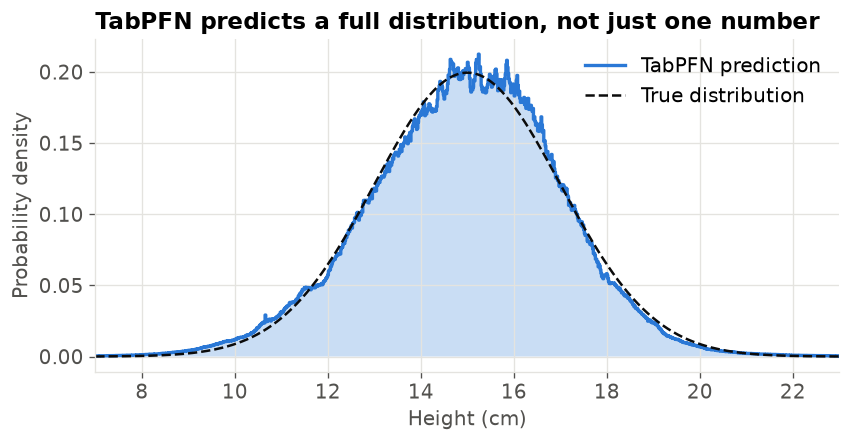

Predicted mean: 15.0 cm (true mean: 15.0 cm)


In [3]:
height_model = new_model().fit(toy_X, toy_Y[:, 0])
full = height_model.predict(pd.DataFrame({"sunlight": [6.0]}), output_type="full")

borders = full["borders"]
probs = np.exp(full["logits"][0] - full["logits"][0].max())
probs /= probs.sum()
density = probs / np.diff(borders)  # probability per cm

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(borders[:-1], density, step="post", color=COLORS["Copula"], alpha=0.25, lw=0)
ax.step(borders[:-1], density, where="post", color=COLORS["Copula"], lw=2, label="TabPFN prediction")
grid = np.linspace(7, 23, 300)
ax.plot(grid, norm.pdf(grid, 15, 2), color=INK, lw=1.5, ls="--", label="True distribution")
ax.set(xlim=(7, 23), xlabel="Height (cm)", ylabel="Probability density")
ax.set_title("TabPFN predicts a full distribution, not just one number")
ax.legend(loc="upper right")
plt.show()
print(f"Predicted mean: {full['mean'][0]:.1f} cm (true mean: 15.0 cm)")

In this recipe we read these distributions through their **quantiles**. The 30% quantile is the height that the plant is below with 30% probability. With quantiles at many levels (0.5%, 1%, ..., 99.5%) we can do two useful things:

1. **Draw random samples.** Pick a random percentile, for example 72%, and read off the value at that quantile. Repeat this many times and you get a cloud of plausible outcomes.
2. **Find where a real value falls.** Given an observed height, find its percentile in the predicted distribution. We use this for the copula below.

The helpers below do exactly these two things for many rows at once. `percentiles` is an array of numbers between 0 and 1.

In [4]:
LEVELS = np.round(np.linspace(0.005, 0.995, 199), 3)


def quantile_table(model, X):
    """Predicted value at each level in LEVELS, one row per row of X."""
    q = np.asarray(model.predict(X, output_type="quantiles", quantiles=list(LEVELS))).T
    return np.maximum.accumulate(q, axis=1)


def value_at(table, percentiles):
    """Read each row's predicted distribution at the given percentiles (one row of percentiles per table row)."""
    pos = np.clip((percentiles - LEVELS[0]) / (LEVELS[1] - LEVELS[0]), 0, len(LEVELS) - 1)
    lo = np.minimum(np.floor(pos).astype(int), len(LEVELS) - 2)
    w = pos - lo
    rows = np.arange(len(table))[:, None]
    return table[rows, lo] * (1 - w) + table[rows, lo + 1] * w


def percentile_of(table, y):
    """Where each observed y falls in its own row's predicted distribution (a number between 0 and 1)."""
    return np.array([np.interp(v, row, LEVELS) for row, v in zip(table, y)])

## Three ways to predict two targets together

A **joint prediction** answers "which (height, width) pairs are likely?". We will represent it by drawing, say, 200 plausible pairs for each plant. A good joint prediction has two properties: each target on its own is right (the **marginals**), and the targets move together in the right way (the **dependence**).

### 1. Independent

Fit one TabPFN model for height and one for width, each from sunlight only. To draw a pair, draw a height from the height model and, **separately**, a width from the width model.

A worked example for a plant with 6 hours of sun. Say the height model predicts "about 15 cm, give or take 2" and the width model "about 5.8 cm, give or take 1". Four independent draws could look like this:

| Draw | Height percentile | Height (cm) | Width percentile | Width (cm) |
|---|---|---|---|---|
| 1 | 90% | 17.6 | 15% | 4.8 |
| 2 | 20% | 13.3 | 85% | 6.8 |
| 3 | 55% | 15.3 | 50% | 5.8 |
| 4 | 10% | 12.4 | 95% | 7.4 |

Each column on its own is fine. But draws 1, 2 and 4 combine a tall plant with a narrow one, or the other way round. In our data such plants are rare, because the surprises are correlated. The independent method throws this information away.

### 2. Chained

Use the rule from probability: *P(height, width) = P(height) × P(width given height)*.

- Model 1 predicts **height** from sunlight (the same model as before).
- Model 2 predicts **width** from sunlight **and the true height**. During training we know both targets, so we can give the true height to model 2 as an extra input column.

To draw a pair, draw a height from model 1, then give that drawn height to model 2 and draw a width from its prediction:

| Draw | Height drawn by model 1 | Model 2 sees | Model 2 predicts width | Width drawn |
|---|---|---|---|---|
| 1 | 17.6 | sun = 6, height = 17.6 | about 6.9, give or take 0.5 | 7.1 |
| 2 | 13.3 | sun = 6, height = 13.3 | about 5.0, give or take 0.5 | 4.8 |

Now a tall plant gets a wide width, and the spread of model 2 is smaller, because knowing the height tells it a lot. The price: model 2 must make a prediction for **every draw** (200 draws × number of plants), and the result can depend on which target we put first.

### 3. Copula

Keep the two independent models, and learn one extra number (or a small matrix for more targets) that describes how their errors move together. A **copula** is this "glue" between distributions. We use the simplest one, the **Gaussian copula**, in four steps:

1. **Percentiles of the truth.** For each training plant, find where its true height falls in its predicted height distribution, for example at the 84th percentile. Do the same for width.
2. **Normal scores.** Turn each percentile into a z-score of a standard normal distribution: 50% → 0, 84% → 1.0, 16% → -1.0.
3. **Correlation.** Compute the correlation of the height z-scores with the width z-scores over all training plants. If tall-for-its-sunlight plants are also wide-for-their-sunlight, this correlation is high.
4. **Sampling.** Draw pairs of correlated z-scores with that correlation, turn them back into percentiles, and read each target's prediction at its percentile.

A small worked example with five training plants (made-up numbers):

| Plant | Height percentile | Height z | Width percentile | Width z |
|---|---|---|---|---|
| A | 84% | 1.0 | 79% | 0.8 |
| B | 31% | -0.5 | 38% | -0.3 |
| C | 50% | 0.0 | 62% | 0.3 |
| D | 7% | -1.5 | 12% | -1.2 |
| E | 69% | 0.5 | 58% | 0.2 |

The two z columns go up and down together, so their correlation is high (about 0.97 here). When we sample, a plant drawn at the 90th height percentile will usually also be drawn at a high width percentile.

One detail matters for step 1. TabPFN learns from the training rows it is given (its "context"). If a plant is in the context, the model has already seen its true height, so the percentile is too close to 50% and the correlation would be wrong. We therefore compute each training plant's percentile with a model that did **not** see it: we split the training data into 5 parts and, for each part, use a model fitted on the other 4 parts. This is called **cross-fitting**.

In [5]:
def fit_independent(X, Y):
    return [new_model().fit(X, Y[:, k]) for k in range(Y.shape[1])]


def fit_copula_correlation(X, Y, splitter, groups=None):
    """Steps 1-3: cross-fitted percentiles of the truth, normal scores, correlation."""
    percentiles = np.zeros_like(Y)
    for fit_rows, held_rows in splitter.split(X, groups=groups):
        for k in range(Y.shape[1]):
            model = new_model().fit(X.iloc[fit_rows], Y[fit_rows, k])
            table = quantile_table(model, X.iloc[held_rows])
            percentiles[held_rows, k] = percentile_of(table, Y[held_rows, k])
    z = norm.ppf(percentiles)
    return np.corrcoef(z, rowvar=False), percentiles


def with_targets(X, values, names):
    """Add (true or drawn) target values as extra input columns."""
    X = X.reset_index(drop=True).copy()
    for j, name in enumerate(names):
        X[name] = values[:, j]
    return X


def fit_chain(X, Y, names, first_model):
    """Model k predicts target k from the inputs plus the true targets 0..k-1."""
    later = [new_model().fit(with_targets(X, Y[:, :k], names[:k]), Y[:, k])
             for k in range(1, Y.shape[1])]
    return [first_model] + later

Sampling then takes only a few lines. All three methods produce an array of shape *(rows, draws, targets)*. The independent and copula methods read **the same** predicted distributions; they differ only in how they choose the percentiles: random and unrelated for independent, correlated for the copula.

In [6]:
def sample_independent(tables, n_draws, rng):
    n, d = len(tables[0]), len(tables)
    percentiles = rng.uniform(size=(n, n_draws, d))
    return np.stack([value_at(tables[k], percentiles[..., k]) for k in range(d)], axis=-1)


def sample_copula(tables, correlation, n_draws, rng):
    n, d = len(tables[0]), len(tables)
    z = rng.multivariate_normal(np.zeros(d), correlation, size=(n, n_draws))
    percentiles = norm.cdf(z)
    return np.stack([value_at(tables[k], percentiles[..., k]) for k in range(d)], axis=-1)


def sample_chain(chain, first_table, X, names, n_draws, rng):
    n, d = len(X), len(chain)
    X_repeated = X.reset_index(drop=True).loc[np.repeat(np.arange(n), n_draws)]
    draws = np.zeros((n * n_draws, d))
    draws[:, 0] = value_at(first_table, rng.uniform(size=(n, n_draws))).ravel()
    for k in range(1, d):
        table = quantile_table(chain[k], with_targets(X_repeated, draws[:, :k], names[:k]))
        draws[:, k] = value_at(table, rng.uniform(size=(n * n_draws, 1))).ravel()
    return draws.reshape(n, n_draws, d)

### The three methods on the toy plants

We fit all three on the 300 toy plants and draw 400 (height, width) pairs for a new plant with 6 hours of sunlight. Because the data is made up, we can also draw from the **true** joint distribution and compare.

In [7]:
toy_names = ["height", "width"]
toy_new = pd.DataFrame({"sunlight": [6.0]})
toy_models = fit_independent(toy_X, toy_Y)
toy_tables = [quantile_table(m, toy_new) for m in toy_models]
toy_corr, toy_pct = fit_copula_correlation(toy_X, toy_Y, KFold(5, shuffle=True, random_state=0))
toy_chain = fit_chain(toy_X, toy_Y, toy_names, toy_models[0])

toy_draws = {
    "Independent": sample_independent(toy_tables, 400, rng)[0],
    "Chained": sample_chain(toy_chain, toy_tables[0], toy_new, toy_names, 400, rng)[0],
    "Copula": sample_copula(toy_tables, toy_corr, 400, rng)[0],
}
truth_draws = grow_plants(np.full(400, 6.0), rng)
print(f"Correlation learned by the copula: {toy_corr[0, 1]:.2f} (true value: 0.85)")
display(pd.DataFrame({
    "Height percentile": toy_pct[:5, 0], "Height z": norm.ppf(toy_pct[:5, 0]),
    "Width percentile": toy_pct[:5, 1], "Width z": norm.ppf(toy_pct[:5, 1]),
}).round(2).rename_axis("Training plant"))

Correlation learned by the copula: 0.83 (true value: 0.85)


,Height percentile,Height z,Width percentile,Width z
Training plant,,,,
0,0.36,-0.37,0.27,-0.63
1,0.48,-0.04,0.25,-0.68
2,0.10,-1.31,0.36,-0.37
3,0.23,-0.73,0.38,-0.30
4,1.00,2.58,1.00,2.58


The table shows steps 1 and 2 of the copula for the first five real training plants. Plant 4 is much taller and wider than usual for its sunlight: its true values lie beyond the 99.5% quantile, so its percentile is capped at the edge of our quantile grid (shown rounded as 1.00). Now the picture:

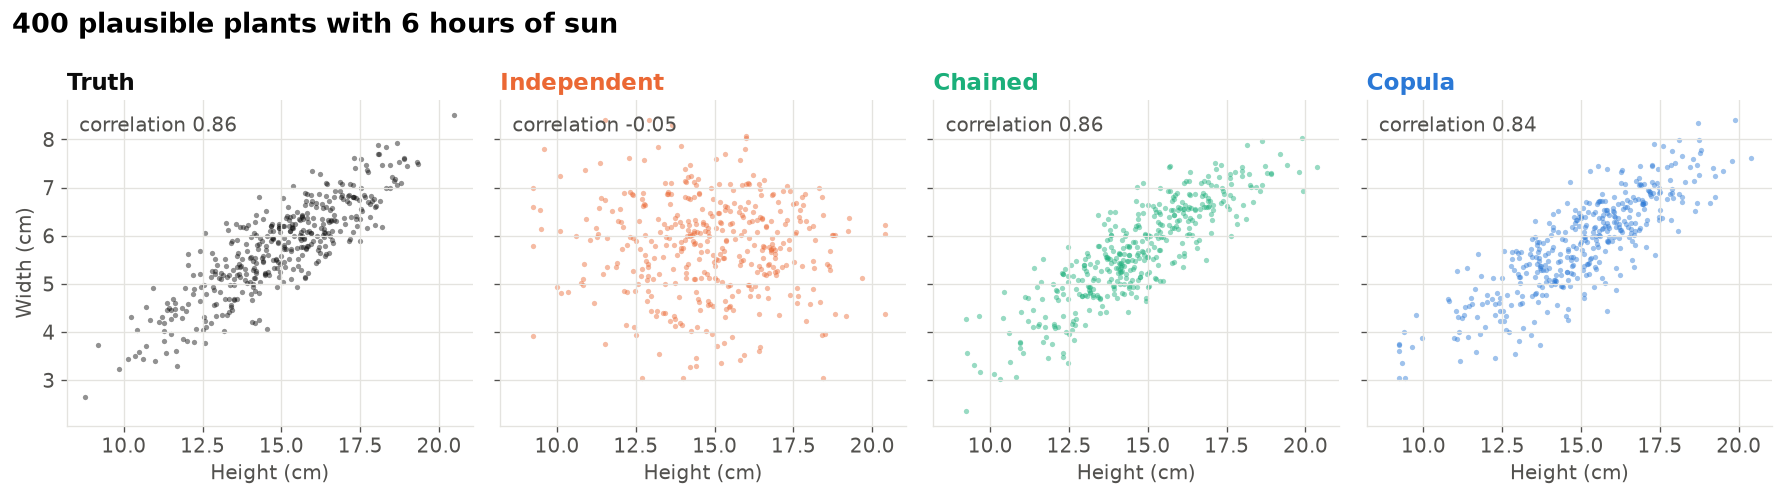

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharex=True, sharey=True)
panels = [("Truth", INK, truth_draws)] + [(k, COLORS[k], v) for k, v in toy_draws.items()]
for ax, (name, color, d) in zip(axes, panels):
    ax.scatter(d[:, 0], d[:, 1], s=10, color=color, alpha=0.45, lw=0)
    r = np.corrcoef(d[:, 0], d[:, 1])[0, 1]
    ax.set_title(name, color=color)
    ax.text(0.03, 0.95, f"correlation {r:.2f}", transform=ax.transAxes, va="top", color=MUTED)
    ax.set_xlabel("Height (cm)")
axes[0].set_ylabel("Width (cm)")
fig.suptitle("400 plausible plants with 6 hours of sun", x=0.01, ha="left",
             fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

All four clouds have about the same horizontal and vertical spread: each target **on its own** is predicted well by every method. The difference is the **shape**. The true cloud is a tilted ellipse. The independent cloud is round, because it ignores the link between height and width. The chained and copula clouds recover the tilt.

## How to score a joint prediction

We need one number that says how good a cloud of draws is, given the real outcome. We use the **energy score**. For one row with true outcome *y* and draws *x₁, ..., xₘ*:

*energy score = (average distance from a draw to the truth) − ½ × (average distance between two draws)*

- The first part rewards clouds that are **close to the truth**.
- The second part rewards clouds that are **spread out**. Without it, the best strategy would be to put every draw on one confident point. The two parts together reward a cloud that is exactly as wide as it needs to be.
- **Lower is better.** Distances are Euclidean, so all targets count together.

A tiny worked example with the truth at (0, 0) and three draws:

| Draw | Position | Distance to truth |
|---|---|---|
| x₁ | (1, 0) | 1.00 |
| x₂ | (0, 1) | 1.00 |
| x₃ | (1, 1) | 1.41 |

Average distance to the truth: (1 + 1 + 1.41) / 3 = 1.14. Distances between pairs of draws: x₁–x₂ = 1.41, x₁–x₃ = 1, x₂–x₃ = 1, average 1.14. Energy score = 1.14 − ½ × 1.14 = **0.57**.

With a single target, the energy score is the well-known **CRPS** (continuous ranked probability score). We report the CRPS of each target too. It only looks at one target at a time, so it tells us whether a method gets the marginals right, independently of the dependence.

Targets can have very different units, so before scoring we convert each target to **standard units**: subtract the training mean and divide by the training standard deviation.

In [9]:
def energy_score(draws, y):
    """Average energy score over rows. draws: (rows, draws, targets), y: (rows, targets)."""
    to_truth = np.linalg.norm(draws - y[:, None, :], axis=-1).mean(axis=1)
    between = np.array([pdist(row).mean() for row in draws])
    return float(np.mean(to_truth - 0.5 * between))


print(f"Worked example: {energy_score(np.array([[[1, 0], [0, 1], [1, 1]]]), np.array([[0, 0]])):.2f}")

Worked example: 0.57


## Real data from ScoringBench

We use two small multi-target datasets from the ScoringBench multivariate list, loaded from OpenML. Both have strongly linked targets.

**Weather in Ankara** ([OpenML 42368](https://www.openml.org/d/42368)). 321 days of weather measurements. The targets are the day's **minimum temperature**, **maximum temperature** and **dew point** (the temperature at which dew forms, a measure of humidity), all converted to °C. The inputs are the other measurements of the same day: precipitation, air pressure, visibility and wind speed. Like ScoringBench, we drop the mean temperature (it would give the answer away) and the maximum wind speed. The minimum temperature is never above the maximum temperature, so this dataset can also show us how often each method produces impossible days.

**Skin lesions** ([OpenML 46630](https://www.openml.org/d/46630), from the PAD-UFES-20 dataset). Patient information and symptoms for skin lesions photographed with smartphones. The two targets are the lesion's two **diameters** in mm. The inputs include age, skin type, body region, the diagnosis and symptoms such as itching or bleeding. We keep the 1,494 images with both diameters (one row per image) and drop the identifier columns.

**Why we split by patient.** The rows are not independent. The 1,494 images come from 1,134 lesions and 794 patients. 314 lesions were photographed more than once, and these repeat rows have exactly the same diameters. Many inputs, such as age, skin type and family history, are also the same for every row of a patient. With a random row split, a copy of a test lesion would often be in the training data, and the model could simply look up its diameters: the score would look much better than it would be for a new patient. So we use `GroupKFold` with `patient_id` as the group: all rows of one patient are either in the training data or in the test data, never in both. The inner split that fits the copula correlation is grouped in the same way. Only the split uses the patient: the model still trains and predicts one row (one image) at a time, and the scores are averaged over rows.

We evaluate each dataset with 5-fold cross-validation: every row is a test row exactly once, predicted by models that never saw it.

In [10]:
weather = fetch_openml(data_id=42368, as_frame=True).frame
weather_targets = ["Min_temperature", "Max_temperature", "Dewpoint"]
weather_Y = ((weather[weather_targets] - 32) * 5 / 9).to_numpy()  # °F -> °C
weather_X = weather.drop(columns=weather_targets + ["Mean_temperature", "Max_wind_speed"])

skin = fetch_openml(data_id=46630, as_frame=True).frame
skin = skin.dropna(subset=["diameter_1", "diameter_2"]).reset_index(drop=True)
skin_targets = ["diameter_1", "diameter_2"]
skin_Y = skin[skin_targets].to_numpy()
skin_X = skin.drop(columns=skin_targets + ["patient_id", "lesion_id", "img_id"])

datasets = {
    "Weather (Ankara)": dict(X=weather_X, Y=weather_Y, names=weather_targets, groups=None,
                             splitter=KFold(5, shuffle=True, random_state=0)),
    # Split by patient: repeat images of one lesion share its diameters,
    # so a random row split would leak test answers into training.
    "Skin lesions": dict(
        X=skin_X, Y=skin_Y, names=skin_targets, groups=skin["patient_id"],
        splitter=GroupKFold(5, shuffle=True, random_state=0),
    ),
}
for name, ds in datasets.items():
    print(f"{name}: {len(ds['X'])} rows, {ds['X'].shape[1]} inputs, targets {ds['names']}")

Weather (Ankara): 321 rows, 5 inputs, targets ['Min_temperature', 'Max_temperature', 'Dewpoint']
Skin lesions: 1494 rows, 21 inputs, targets ['diameter_1', 'diameter_2']


Before modelling, a look at how linked the targets are. Each point is one row of the data.

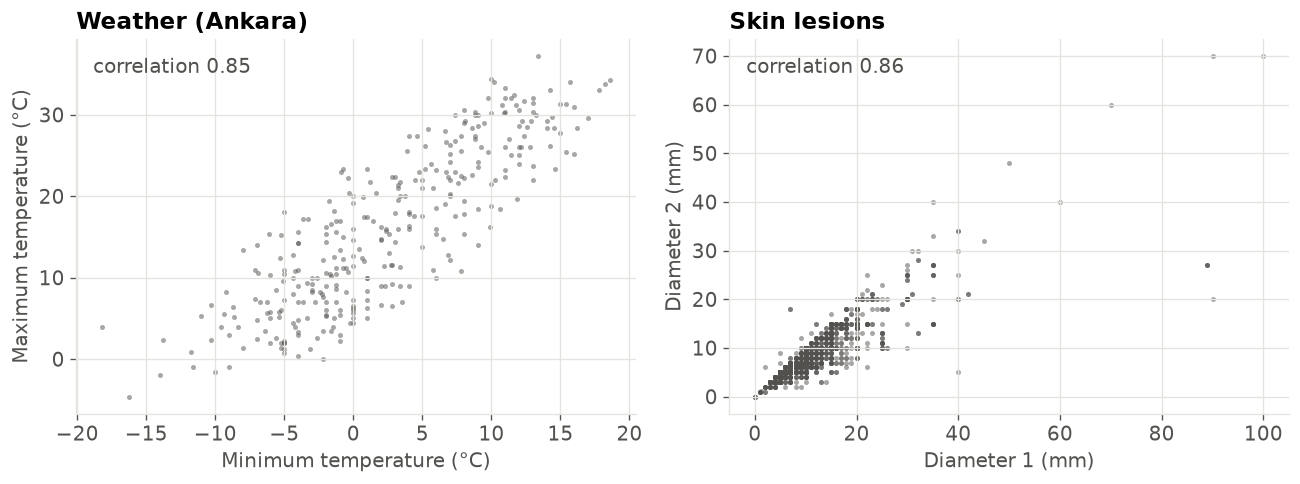

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pairs = [("Weather (Ankara)", 0, 1, "Minimum temperature (°C)", "Maximum temperature (°C)"),
         ("Skin lesions", 0, 1, "Diameter 1 (mm)", "Diameter 2 (mm)")]
for ax, (name, i, j, xl, yl) in zip(axes, pairs):
    Y = datasets[name]["Y"]
    ax.scatter(Y[:, i], Y[:, j], s=9, color=MUTED, alpha=0.5, lw=0)
    ax.set(xlabel=xl, ylabel=yl, title=name)
    ax.text(0.03, 0.95, f"correlation {np.corrcoef(Y[:, i], Y[:, j])[0, 1]:.2f}",
            transform=ax.transAxes, va="top", color=MUTED)
fig.tight_layout()
plt.show()

These correlations mix two things: the part the inputs explain (a sunny day is warm both at night and in the afternoon) and the part they do not. Only the second part, the link between the **surprises**, can help a joint model beat the independent one.

## Run the comparison

For each fold we fit the models on the training rows, draw 200 joint samples for every test row with each method, and score them. For the chained method we keep the target order shown above. The same random number generator is used throughout so that the run is reproducible.

In [12]:
N_DRAWS = 200
rng = np.random.default_rng(42)
rows, kept = [], {}

for name, ds in datasets.items():
    X, Y, names = ds["X"], ds["Y"], ds["names"]
    groups = ds["groups"]
    for fold, (train, test) in enumerate(ds["splitter"].split(X, groups=groups)):
        X_train, Y_train, X_test, Y_test = X.iloc[train], Y[train], X.iloc[test], Y[test]
        train_groups = None if groups is None else groups.iloc[train]
        inner = GroupKFold(5, shuffle=True, random_state=0) if groups is not None else KFold(5, shuffle=True, random_state=0)

        marginals = fit_independent(X_train, Y_train)
        tables = [quantile_table(m, X_test) for m in marginals]
        correlation, _ = fit_copula_correlation(X_train, Y_train, inner, train_groups)
        chain = fit_chain(X_train, Y_train, names, marginals[0])

        draws = {
            "Independent": sample_independent(tables, N_DRAWS, rng),
            "Chained": sample_chain(chain, tables[0], X_test, names, N_DRAWS, rng),
            "Copula": sample_copula(tables, correlation, N_DRAWS, rng),
        }
        mean, std = Y_train.mean(axis=0), Y_train.std(axis=0)
        y_std = (Y_test - mean) / std
        for method, d in draws.items():
            d_std = (d - mean) / std
            row = {"Dataset": name, "Fold": fold, "Method": method,
                   "Energy score": energy_score(d_std, y_std)}
            for k, target in enumerate(names):
                row[f"CRPS {target}"] = energy_score(d_std[..., [k]], y_std[:, [k]])
            rows.append(row)
        kept.setdefault(name, []).append(dict(test=test, draws=draws, correlation=correlation,
                                              truth_pct=np.column_stack([percentile_of(t, Y_test[:, k])
                                                                         for k, t in enumerate(tables)])))
        print(f"{name} fold {fold} done")

results = pd.DataFrame(rows)

Weather (Ankara) fold 0 done
Weather (Ankara) fold 1 done
Weather (Ankara) fold 2 done
Weather (Ankara) fold 3 done
Weather (Ankara) fold 4 done
Skin lesions fold 0 done
Skin lesions fold 1 done
Skin lesions fold 2 done
Skin lesions fold 3 done
Skin lesions fold 4 done


## Results

### Energy score

The table shows the energy score averaged over the five folds (lower is better). The chart shows the change relative to the independent method, in percent: below zero means better than independent. Each dot is one fold.

Method,Independent,Chained,Copula
Dataset,,,
Weather (Ankara),0.449,0.444,0.445
Skin lesions,0.675,0.648,0.653


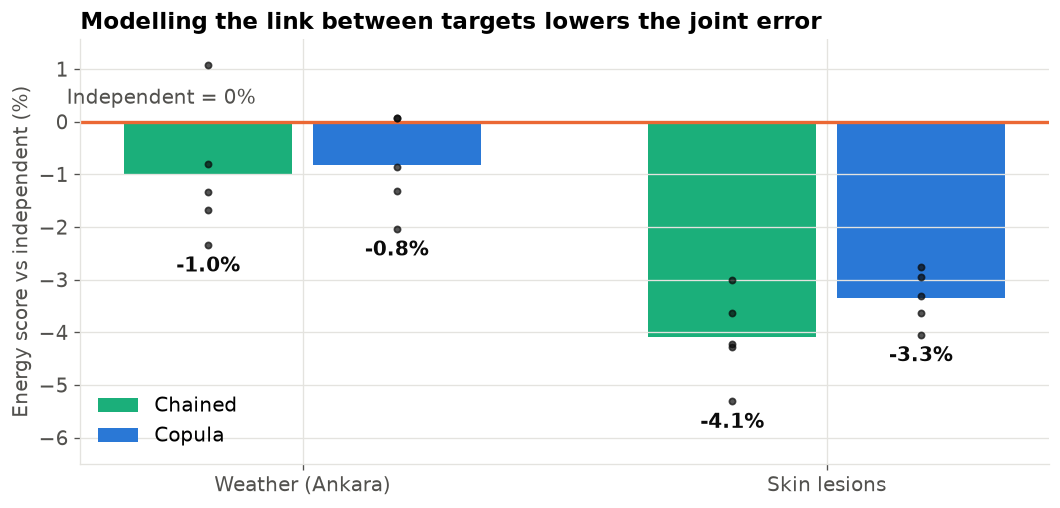

In [13]:
order = list(COLORS)
summary = results.groupby(["Dataset", "Method"], sort=False)["Energy score"].mean().unstack()[order]
display(summary.round(3))

rel = results.pivot_table(index=["Dataset", "Fold"], columns="Method", values="Energy score")
rel = (rel.div(rel["Independent"], axis=0) - 1) * 100

fig, ax = plt.subplots(figsize=(9, 4.4))
names_ds = list(datasets)
width = 0.36
for i, method in enumerate(["Chained", "Copula"]):
    for j, ds_name in enumerate(names_ds):
        vals = rel.loc[ds_name, method]
        x = j + (i - 0.5) * width
        ax.bar(x, vals.mean(), width=width - 0.04, color=COLORS[method],
               label=method if j == 0 else None)
        ax.scatter(np.full(len(vals), x), vals, color=INK, s=14, zorder=3, alpha=0.7)
        ax.annotate(f"{vals.mean():+.1f}%", (x, min(vals.min(), vals.mean())), xytext=(0, -16),
                    textcoords="offset points", ha="center", color=INK, fontsize=12, fontweight="bold")
ax.axhline(0, color=COLORS["Independent"], lw=2)
ax.text(-0.45, 0.25, "Independent = 0%", color=MUTED, ha="left", va="bottom")
ax.set_ylim(rel[["Chained", "Copula"]].min().min() - 1.2, max(1.5, rel[["Chained", "Copula"]].max().max() + 0.5))
ax.set_xticks(range(len(names_ds)), names_ds)
ax.set_ylabel("Energy score vs independent (%)")
ax.set_title("Modelling the link between targets lowers the joint error")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

Both joint methods beat the independent method on both datasets. On the skin lesions the gain is clear and holds in every fold. On the weather data it is small: most folds improve, but one fold of each method is level with independent or slightly worse. The chained method is a little ahead of the copula on both datasets.

### Each target on its own

The CRPS of each target checks the marginals. The independent and copula methods use exactly the same marginal distributions, so they differ only by random sampling noise. The chained method has different marginals for every target after the first one, because those targets are predicted from drawn values of the earlier targets.

In [14]:
crps_cols = [c for c in results.columns if c.startswith("CRPS")]
crps = results.groupby(["Dataset", "Method"], sort=False)[crps_cols].mean()
for name in datasets:
    display(crps.loc[name].dropna(axis=1).round(3).rename_axis(name))

,CRPS Min_temperature,CRPS Max_temperature,CRPS Dewpoint
Weather (Ankara),,,
Independent,0.220,0.207,0.253
Chained,0.220,0.208,0.253
Copula,0.221,0.207,0.254


,CRPS diameter_1,CRPS diameter_2
Skin lesions,,
Independent,0.423,0.457
Chained,0.423,0.452
Copula,0.424,0.457


Target by target, the three methods are almost identical. So the energy score gain above does **not** come from better individual predictions: it comes from getting the link between the targets right. The only visible marginal difference is the chained method's small gain on the second diameter, which it predicts from the drawn first diameter.

### Impossible weather days

On a real day, the minimum temperature is never above the maximum. How often does each method still draw such a day?

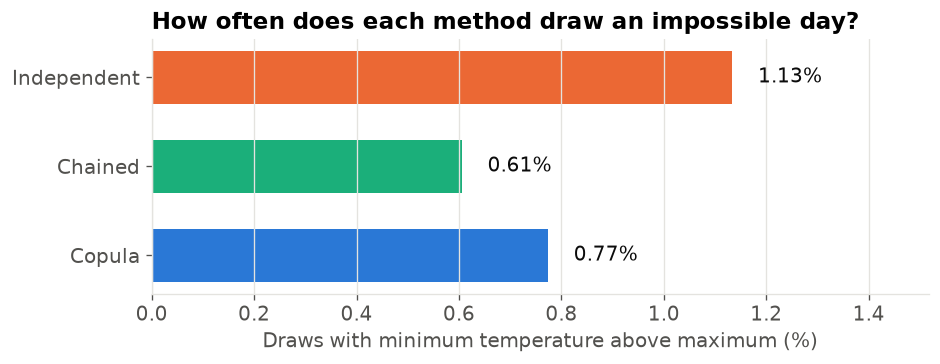

In [15]:
impossible = {}
for method in order:
    d = np.concatenate([f["draws"][method] for f in kept["Weather (Ankara)"]])
    impossible[method] = 100 * np.mean(d[..., 0] > d[..., 1])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(order[::-1], [impossible[m] for m in order[::-1]],
        color=[COLORS[m] for m in order[::-1]], height=0.6)
for i, m in enumerate(order[::-1]):
    ax.text(impossible[m] + 0.05, i, f"{impossible[m]:.2f}%", va="center", color=INK)
ax.set_xlabel("Draws with minimum temperature above maximum (%)")
ax.set_title("How often does each method draw an impossible day?")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(impossible.values()) * 1.25 + 0.1)
fig.tight_layout()
plt.show()

Impossible days are rare for every method, because the predicted minimum is usually well below the predicted maximum. Still, the independent method draws them most often, roughly twice as often as the chained method. The copula sits in between. Neither joint method removes them completely: they learn that the two temperatures move together, not the hard rule that one is always below the other.

### What the joint predictions look like

For one test row of each dataset we plot the 200 draws of each method together with the real outcome (black star). We pick a typical row: the one whose independent predictions have the median spread. For the weather we show minimum temperature against dew point, the pair with the strongest link (see the next section). Axes show the central 98% of the draws.

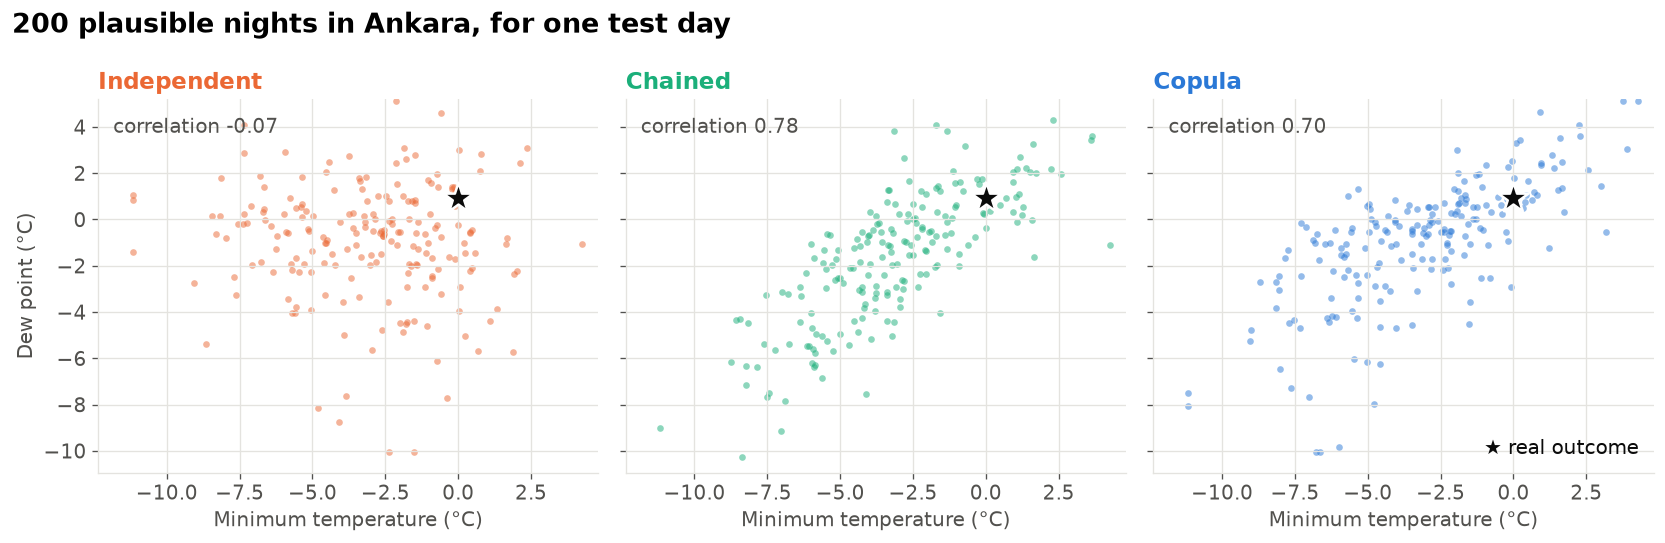

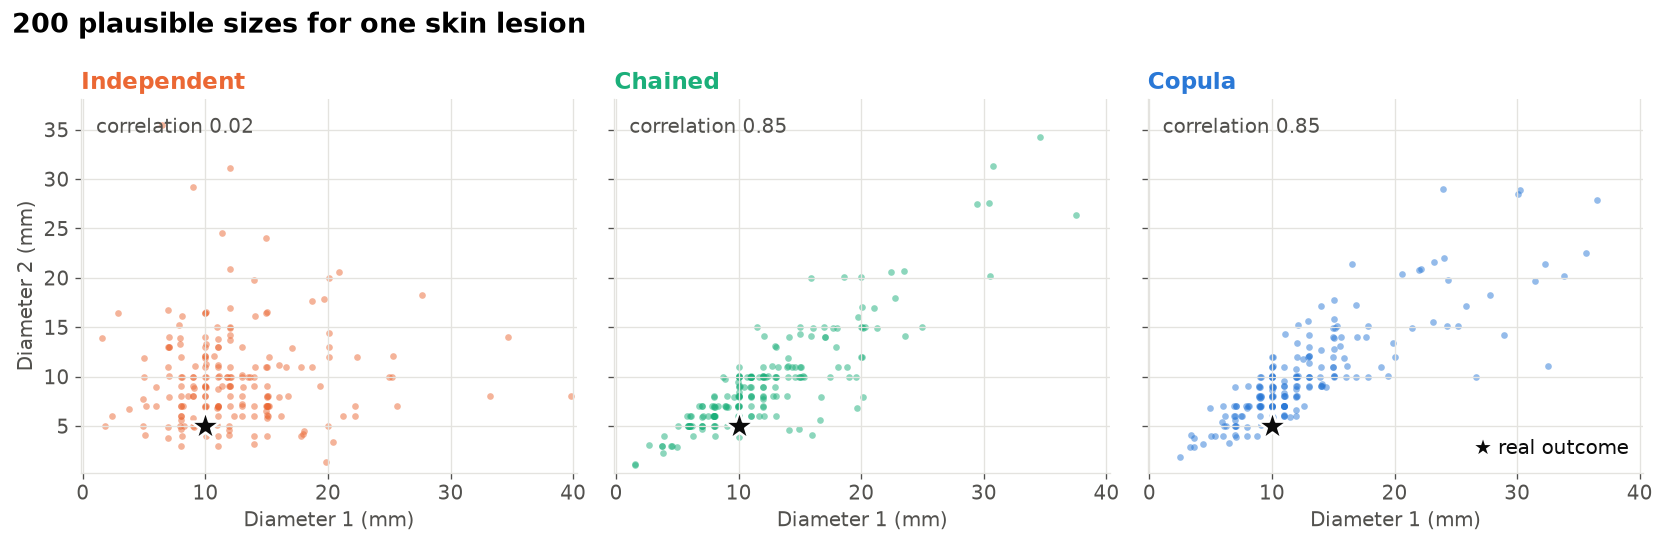

In [16]:
def cloud_figure(ds_name, i, j, xl, yl, title):
    folds = kept[ds_name]
    draws = {m: np.concatenate([f["draws"][m] for f in folds]) for m in order}
    test = np.concatenate([f["test"] for f in folds])
    Y = datasets[ds_name]["Y"][test]
    spread = draws["Independent"][..., i].std(axis=1) + draws["Independent"][..., j].std(axis=1)
    r = int(np.argsort(spread)[len(spread) // 2])  # a typical row: median spread
    pooled = np.concatenate([draws[m][r] for m in order])
    lims = [np.percentile(pooled[:, c], [1, 99]) for c in (i, j)]
    pad = [0.08 * (hi - lo) for lo, hi in lims]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
    for ax, m in zip(axes, order):
        d = draws[m][r]
        ax.scatter(d[:, i], d[:, j], s=16, color=COLORS[m], alpha=0.5, lw=0)
        ax.scatter(Y[r, i], Y[r, j], marker="*", s=360, color=INK, edgecolor="white", lw=1.5, zorder=4)
        ax.set_title(m, color=COLORS[m])
        ax.text(0.03, 0.95, f"correlation {np.corrcoef(d[:, i], d[:, j])[0, 1]:.2f}",
                transform=ax.transAxes, va="top", color=MUTED)
        ax.set_xlabel(xl)
    axes[0].set(ylabel=yl, xlim=(lims[0][0] - pad[0], lims[0][1] + pad[0]),
                ylim=(lims[1][0] - pad[1], lims[1][1] + pad[1]))
    axes[-1].text(0.97, 0.05, "★ real outcome", transform=axes[-1].transAxes, ha="right", color=INK)
    fig.suptitle(title, x=0.01, ha="left", fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()


cloud_figure("Weather (Ankara)", 0, 2, "Minimum temperature (°C)", "Dew point (°C)",
             "200 plausible nights in Ankara, for one test day")
cloud_figure("Skin lesions", 0, 1, "Diameter 1 (mm)", "Diameter 2 (mm)",
             "200 plausible sizes for one skin lesion")

### The glue the copula learns

The copula's correlation describes how the **surprises** move together. We can check it on the test rows: for each test row, take the percentile of the true value in the independent prediction, for each target. If the targets' surprises were unrelated, these points would fill the square evenly. Points along the diagonal mean "when one target is higher than predicted, the other one is too".

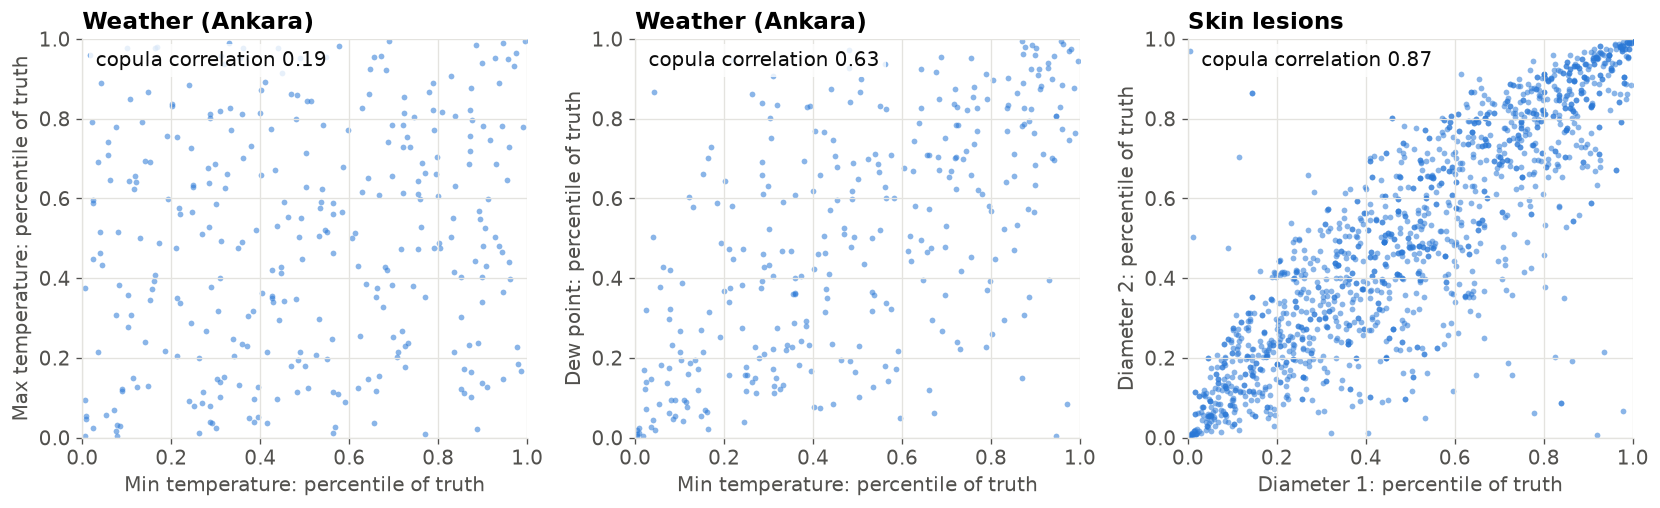

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
checks = [("Weather (Ankara)", 0, 1, "Min temperature", "Max temperature"),
          ("Weather (Ankara)", 0, 2, "Min temperature", "Dew point"),
          ("Skin lesions", 0, 1, "Diameter 1", "Diameter 2")]
for ax, (ds_name, i, j, a, b) in zip(axes, checks):
    pct = np.concatenate([f["truth_pct"] for f in kept[ds_name]])
    learned = np.mean([f["correlation"][i, j] for f in kept[ds_name]])
    ax.scatter(pct[:, i], pct[:, j], s=12, color=COLORS["Copula"], alpha=0.55, lw=0)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel=f"{a}: percentile of truth",
           ylabel=f"{b}: percentile of truth", title=ds_name)
    ax.text(0.03, 0.97, f"copula correlation {learned:.2f}", transform=ax.transAxes,
            va="top", color=INK, bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
fig.tight_layout()
plt.show()

The three panels explain the size of the gains. For the skin lesions the points lie along the diagonal, and the copula learns a strong correlation: a lesion that is longer than predicted is almost always wider than predicted too. For the weather, the surprises of the minimum and maximum temperature are only weakly linked, so knowing one tells us little about the other. The minimum temperature and the dew point are more strongly linked. The weaker the glue, the less a joint model can gain over the independent one.

## Which method should you use?

- **Independent** is the simplest and cheapest: one model per target. It is the right choice when you only use each target on its own, for example a separate prediction interval for each one. It gives the same per-target quality as the other two methods.
- **Chained** gave the best joint predictions here. It needs one model per target, but every model after the first must predict once **per draw**: with 200 draws, 200 times as many rows. Its result can also depend on the target order. Trying a few orders, or putting the easiest target first, is a good habit.
- **Copula** keeps the independent predictions and adds the link between targets with a few extra fits during training (the cross-fitting). Sampling is then almost free, and the method does not depend on any target order. The Gaussian copula describes the link with correlations only, so it cannot capture, for example, a link that only appears for extreme values. Vine copulas, which ScoringBench uses, are a more flexible option.

When the targets' surprises are strongly linked, as for the two lesion diameters, both joint methods clearly improve on predicting each target alone. When they are only weakly linked, as for the minimum and maximum temperature, the gain is small, and the independent method is a reasonable default.